# 04: Otimizadores × agendas × seeds (task 19)

**Pergunta:** com o mesmo orçamento (920 passos, lote 32, perda MSE em `log1p`), qual otimizador e qual agenda de η treinam melhor o STGCN?

Refazemos o protocolo do desafio 3 com o código novo (`dengue.experimento` e `dengue.varredura`):

| Etapa | O que roda | Seeds |
| --- | --- | --- |
| 1. Baseline | Adam, η = 1e-3, agenda constante | 3 |
| 2. Varredura de η | SGD, SGD Nesterov, Adam, AdamW e Muon, com warmup + cosseno; a grade é estendida quando o melhor η cai na borda | 1 |
| 3. Agendas | os 2 melhores otimizadores e o Muon, cada um no seu melhor η: constante, cosseno, warmup + cosseno e multistep | 1 |
| 4. Confirmação | as 3 melhores combinações | 3 |

A escolha em cada etapa é feita pela **menor perda na validação** (MSE em `log1p`). Também mostramos o MAE na taxa bruta. Para regerar (cerca de 50 min na CPU):

```
python -m dengue.experimento configs/base.yaml
python -m dengue.varredura configs/otimizacao/etapa2.yaml
python -m dengue.varredura configs/otimizacao/etapa3.yaml
python -m dengue.varredura configs/otimizacao/etapa4.yaml
```

Tudo é medido na **validação (2013 a 2015)**. O teste não é usado aqui.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dengue import dados

RES = dados.RAIZ / 'results'
exp = pd.read_csv(RES / 'experimentos.csv')
exp = exp[exp['modelo'].eq('stgcn') & exp['grafo'].eq('geo')]
assert not exp['divergiu'].any()

cores = {'sgd': 'tab:gray', 'sgd_nesterov': 'tab:brown', 'adam': 'tab:blue',
         'adamw': 'tab:green', 'muon': 'tab:purple'}
seed0 = exp[exp['seed'] == 0]
varredura = seed0[seed0['agenda'].eq('warmup_cos') & seed0['id'].str.startswith('e19_')]
varredura.groupby('otimizador', sort=False).apply(
    lambda g: g.loc[g['melhor_val_loss'].idxmin(), ['lr', 'melhor_val_loss', 'mae']],
    include_groups=False).sort_values('melhor_val_loss').round(4)

,lr,melhor_val_loss,mae
otimizador,,,
adamw,0.10,0.0956,0.4384
adam,0.03,0.0969,0.4631
muon,0.01,0.1083,0.5071
sgd,0.30,0.1229,0.5343
sgd_nesterov,0.10,0.1343,0.5760


### Pergunta 1: qual é o melhor η de cada otimizador, e quanto ele importa?

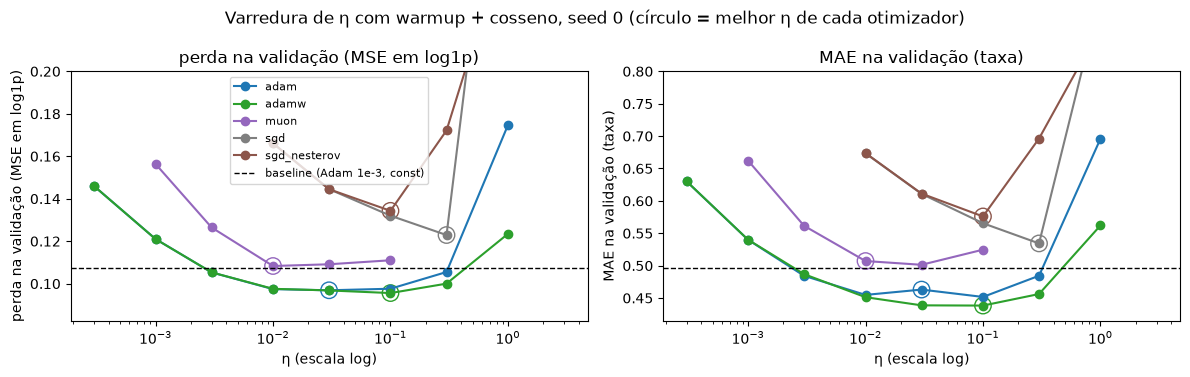

In [2]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for o, g in varredura.sort_values('lr').groupby('otimizador', sort=False):
    for ax, m in zip(eixos, ['melhor_val_loss', 'mae']):
        ax.plot(g['lr'], g[m], marker='o', color=cores[o], label=o)
        melhor = g.loc[g['melhor_val_loss'].idxmin()]
        ax.scatter(melhor['lr'], melhor[m], s=140, facecolors='none', edgecolors=cores[o])
base = exp[exp['id'].eq('e1_base_adam_lr1e-3_const')]
for ax, m, nome in zip(eixos, ['melhor_val_loss', 'mae'],
                       ['perda na validação (MSE em log1p)', 'MAE na validação (taxa)']):
    ax.axhline(base[m].mean(), color='k', ls='--', lw=1, label='baseline (Adam 1e-3, const)')
    ax.set(xscale='log', xlabel='η (escala log)', ylabel=nome, title=nome)
    ax.set_ylim(top=min(ax.get_ylim()[1], 0.2 if m == 'melhor_val_loss' else 0.8))
eixos[0].legend(fontsize=8)
fig.suptitle('Varredura de η com warmup + cosseno, seed 0 (círculo = melhor η de cada otimizador)')
plt.tight_layout()
plt.show()

**Conclusão:** o η importa mais que o otimizador. A mesma família muda a perda em mais de 50% ao longo da grade. Com o melhor η de cada um, a ordem é AdamW (0,1) ≈ Adam (0,03) < Muon (0,01) < SGD (0,3) < SGD Nesterov (0,1). Adam e AdamW têm um **vale largo e plano** entre η = 0,01 e 0,1: qualquer ponto ali empata, e só a partir de 0,3 eles pioram. O baseline (Adam 1e-3) está bem à esquerda desse vale, com um passo pequeno demais. A grade do Adam e do AdamW foi estendida até 1,0 porque o melhor η do AdamW tinha caído na borda (0,1). O SGD perde até no melhor η e se degrada rápido a partir de η = 1 (o gradiente é cortado pelo clip em quase todos os passos).

### Pergunta 2: a agenda de η muda o resultado?

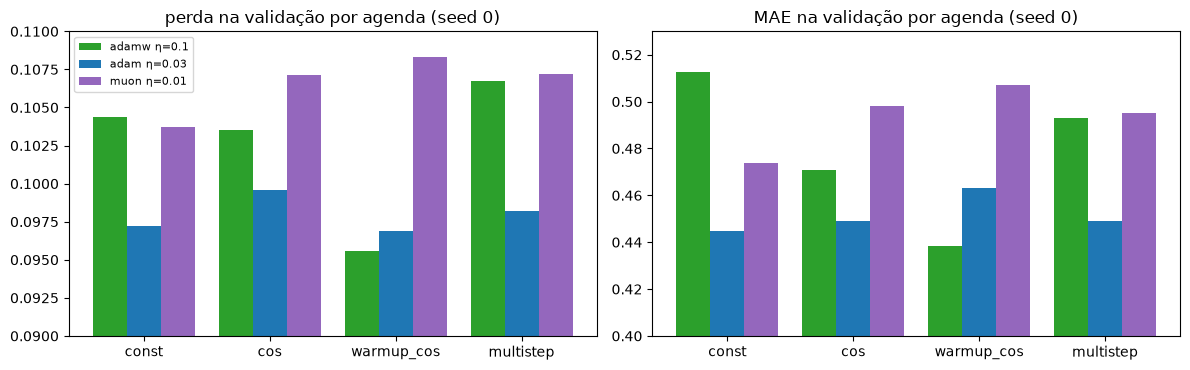

In [3]:
finalistas_e2 = [('adamw', 0.1), ('adam', 0.03), ('muon', 0.01)]
agendas = ['const', 'cos', 'warmup_cos', 'multistep']
no_e3 = np.array([(o, lr) in finalistas_e2 for o, lr in zip(seed0['otimizador'], seed0['lr'])])
e3 = seed0[no_e3 & seed0['id'].str.startswith('e19_')]
x = np.arange(len(agendas))
fig, eixos = plt.subplots(1, 2, figsize=(12, 3.8))
for i, (o, lr) in enumerate(finalistas_e2):
    g = e3[e3['otimizador'].eq(o)].set_index('agenda').loc[agendas]
    for ax, m in zip(eixos, ['melhor_val_loss', 'mae']):
        ax.bar(x + (i - 1) * 0.27, g[m], 0.27, color=cores[o], label=f'{o} η={lr:g}')
for ax, m in zip(eixos, ['perda na validação', 'MAE na validação']):
    ax.set(xticks=x, xticklabels=agendas, title=f'{m} por agenda (seed 0)')
eixos[0].set_ylim(0.09, 0.11)
eixos[1].set_ylim(0.4, 0.53)
eixos[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Conclusão:** depende do η. Com o AdamW em η = 0,1 (alto), a agenda faz muita diferença: o warmup + cosseno é o único que fica bom (0,0956), e a constante e a multistep perdem cerca de 10%. Com η alto, o warmup evita os passos grandes do começo, quando os pesos ainda são aleatórios, e o cosseno reduz o passo no fim para assentar no mínimo. O Adam em η = 0,03 é pouco sensível: as quatro agendas ficam entre 0,097 e 0,100, dentro do ruído de uma seed. O Muon fica atrás em todas. As 3 melhores combinações vão para a etapa 4: AdamW 0,1 warmup_cos, Adam 0,03 warmup_cos e Adam 0,03 const.

### Pergunta 3: com 3 seeds, as finalistas superam o baseline, e quem vence?

In [4]:
grupos = {
    'baseline: Adam 1e-3 const': ('adam', 0.001, 'const'),
    'AdamW 0,1 warmup_cos': ('adamw', 0.1, 'warmup_cos'),
    'Adam 0,03 warmup_cos': ('adam', 0.03, 'warmup_cos'),
    'Adam 0,03 const': ('adam', 0.03, 'const'),
}
colunas = ['melhor_val_loss', 'mae', 'rmse', 'mae_surto']
linhas = {}
for nome, (o, lr, ag) in grupos.items():
    g = exp[exp['otimizador'].eq(o) & np.isclose(exp['lr'], lr) & exp['agenda'].eq(ag)]
    g = g.drop_duplicates('seed')
    assert sorted(g['seed']) == [0, 1, 2], nome
    linhas[nome] = pd.concat([g[colunas].mean().add_suffix('_media'),
                              g[colunas].std().add_suffix('_desvio')])
final = pd.DataFrame(linhas).T
final.round(4).to_csv(RES / 'otimizacao_validacao.csv')
pd.DataFrame({m: [f"{final.loc[n, m + '_media']:.4f} ± {final.loc[n, m + '_desvio']:.4f}"
                  for n in final.index] for m in colunas}, index=final.index)

,melhor_val_loss,mae,rmse,mae_surto
baseline: Adam 1e-3 const,0.1072 ± 0.0007,0.4969 ± 0.0118,2.0706 ± 0.0146,1.7628 ± 0.0031
"AdamW 0,1 warmup_cos",0.0974 ± 0.0025,0.4515 ± 0.0138,1.8820 ± 0.0260,1.5727 ± 0.0423
"Adam 0,03 warmup_cos",0.0986 ± 0.0029,0.4616 ± 0.0062,1.9170 ± 0.0360,1.6312 ± 0.0201
"Adam 0,03 const",0.0982 ± 0.0009,0.4556 ± 0.0123,1.8930 ± 0.0458,1.5794 ± 0.0225


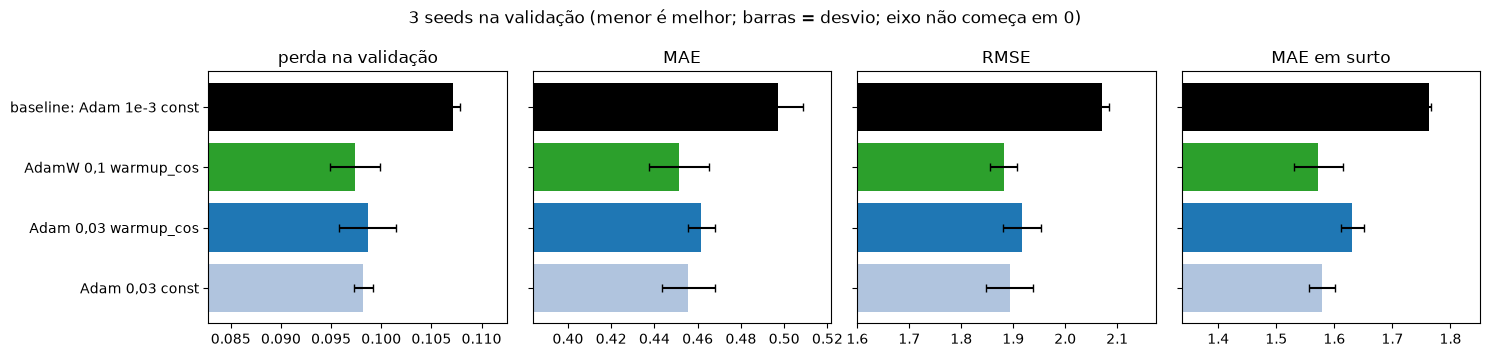

In [5]:
cores_final = ['k', 'tab:green', 'tab:blue', 'lightsteelblue']
fig, eixos = plt.subplots(1, 4, figsize=(15, 3.6))
titulos = {'melhor_val_loss': 'perda na validação', 'mae': 'MAE', 'rmse': 'RMSE',
           'mae_surto': 'MAE em surto'}
for ax, m in zip(eixos, colunas):
    ax.barh(final.index, final[m + '_media'], xerr=final[m + '_desvio'], capsize=3,
            color=cores_final)
    ax.set_title(titulos[m])
    ax.set_xlim(final[m + '_media'].min() * 0.85, final[m + '_media'].max() * 1.05)
    ax.invert_yaxis()
for ax in eixos[1:]:
    ax.set_yticklabels([])
fig.suptitle('3 seeds na validação (menor é melhor; barras = desvio; eixo não começa em 0)')
plt.tight_layout()
plt.show()

**Conclusão:** as três finalistas superam o baseline com folga. A perda cai de 0,107 para cerca de 0,098 (−9%), e o MAE de 0,497 para 0,452 a 0,462. A diferença (cerca de 0,009 na perda) é de 4 a 14 vezes o desvio entre seeds, então é real. **Entre as finalistas é empate:** as diferenças são menores que um desvio. O AdamW 0,1 warmup_cos fica na frente na média (perda 0,0974 ± 0,0025, MAE 0,452 ± 0,014), mas varia mais entre seeds. Para comparação, o AdamW com η = 0,01 e warmup + cosseno, que é a config usada na task 20 (PR #40), deu perda 0,0974 ± 0,0013 e MAE 0,451 ± 0,007: a mesma média, com metade do desvio.

### Pergunta 4: por que o baseline e o SGD ficam para trás?

Duas medidas do log de treino:
- **ρ por camada:** ‖θ depois − θ antes‖ / ‖θ antes‖, o tamanho relativo de cada passo. Mostramos a mediana ao longo do treino.
- **Perda na validação por época:** se a melhor época é a última, o treino foi cortado antes de convergir.

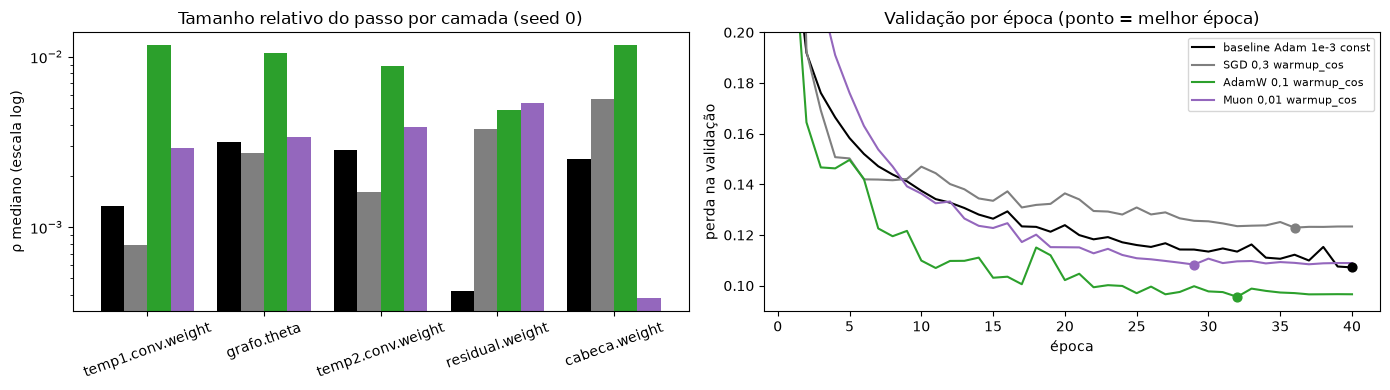

In [6]:
execucoes = {
    'baseline Adam 1e-3 const': 'e1_base_adam_lr1e-3_const',
    'SGD 0,3 warmup_cos': 'e19_sgd_lr0.3_warmup_cos',
    'AdamW 0,1 warmup_cos': 'e19_adamw_lr0.1_warmup_cos',
    'Muon 0,01 warmup_cos': 'e19_muon_lr0.01_warmup_cos',
}
camadas = ['temp1.conv.weight', 'grafo.theta', 'temp2.conv.weight', 'residual.weight',
           'cabeca.weight']
cores_exec = ['k', 'tab:gray', 'tab:green', 'tab:purple']
fig, eixos = plt.subplots(1, 2, figsize=(14, 4))
x = np.arange(len(camadas))
for i, ((nome, ident), cor) in enumerate(zip(execucoes.items(), cores_exec)):
    log = pd.read_csv(RES / 'logs' / f'{ident}_s0.csv')
    rho = [log[f'rho/{c}'].median() for c in camadas]
    eixos[0].bar(x + (i - 1.5) * 0.2, rho, 0.2, color=cor, label=nome)
    val = pd.read_csv(RES / 'logs' / f'{ident}_s0_val.csv')
    eixos[1].plot(val['epoca'], val['perda_val'], color=cor, label=nome)
    melhor = val.loc[val['perda_val'].idxmin()]
    eixos[1].scatter(melhor['epoca'], melhor['perda_val'], color=cor, s=40, zorder=3)
eixos[0].set(yscale='log', xticks=x, xticklabels=camadas, ylabel='ρ mediano (escala log)',
             title='Tamanho relativo do passo por camada (seed 0)')
eixos[0].tick_params(axis='x', labelrotation=20)
eixos[1].set(xlabel='época', ylabel='perda na validação', ylim=(0.09, 0.2),
             title='Validação por época (ponto = melhor época)')
eixos[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Conclusão:**
- **O baseline não convergiu.** A melhor época dele é a última (40 de 40), com a validação ainda caindo, e os passos são pequenos (ρ mediano de 0,0004 a 0,003). Com o mesmo orçamento de 920 passos, o η = 1e-3 não chega ao fundo do vale.
- **O SGD usa um único η para camadas com gradientes de escalas muito diferentes.** O ρ da cabeça é cerca de 7 vezes o da primeira convolução: um η bom para uma camada é grande ou pequeno demais para outra. O Adam e o AdamW dividem o passo pela escala do gradiente de cada peso, e no AdamW o ρ fica parecido em todas as camadas (cerca de 0,01).
- **Ressalva sobre o Muon:** a cabeça dele quase não treina (ρ ≈ 0,0004), porque ela fica no AdamW auxiliar com η fixo em 3e-4, que não foi varrido. O resultado do Muon aqui é, portanto, um limite inferior: não dá para concluir que ele é pior que o AdamW, só que ele é pior nesta configuração. Este é o mesmo achado do desafio 3 (SGD com ρ desbalanceado e baseline com passo pequeno), agora reproduzido com o código novo.

### Resumo e decisão
| Configuração (3 seeds) | Perda na validação | MAE | RMSE | MAE surto |
| --- | --- | --- | --- | --- |
| Baseline: Adam 1e-3, const | 0,1072 ± 0,0007 | 0,497 ± 0,012 | 2,071 ± 0,015 | 1,763 ± 0,003 |
| **AdamW 0,1, warmup_cos** | **0,0974 ± 0,0025** | **0,452 ± 0,014** | **1,882 ± 0,026** | **1,573 ± 0,042** |
| Adam 0,03, warmup_cos | 0,0986 ± 0,0029 | 0,462 ± 0,006 | 1,917 ± 0,036 | 1,631 ± 0,020 |
| Adam 0,03, const | 0,0982 ± 0,0009 | 0,456 ± 0,012 | 1,893 ± 0,046 | 1,579 ± 0,023 |

- Trocar o otimizador e a agenda melhora o STGCN em cerca de 9% na perda e no MAE, sem mudar o modelo.
- **Decisão: AdamW com warmup + cosseno.** Ele é o melhor na média e repete a vencedora do desafio 3. Como o vale do η é plano entre 0,01 e 0,1, recomendamos **η = 0,01** para a avaliação final: dá o mesmo resultado médio (task 20), com metade da variação entre seeds e mais longe da região instável (η ≥ 0,3).
- Fora do escopo: varrer o η do AdamW auxiliar do Muon e o weight decay.